# Pipeline check — positive and negative controls on synthetic data

**Validation of the code, not a strategy attempt** (backtest and OOS counters unchanged). The question: if a real mean-reverting relationship exists, does the exact pipeline used for INTC/AMD find it and make money, in- and out-of-sample? And if none exists, does it correctly find nothing?

Synthetic pairs (8,000 business days, seed 2026, fixed before running): `log P_B` random walk with 2% daily volatility; `log P_A = 0.5 + 0.8·log P_B + s_t` with

- **positive control:** `s_t` Ornstein–Uhlenbeck (AR(1)) with half-life 10 days and stationary sd 0.05;
- **negative control:** `s_t` random walk with the *same* daily innovations (no stable relationship).

Same functions and parameters as INTC/AMD: `fit_hedge_ratio`, `stationarity_tests`, `run_strategy` with e = 2.0, L = 60, `shift(1)`, 5 bp per leg; first half IS (β estimated there only), second half OOS with β frozen.

In [1]:
import logging

import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display
from plotly.subplots import make_subplots

from pairs.plotting import DERIVED_COLOR, apply_style, save_figure
from pairs.synthetic import make_synthetic_pair, run_pipeline_control

logging.basicConfig(level=logging.WARNING)
for noisy in ("kaleido", "choreographer"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

N_DAYS, SEED = 8000, 2026  # fixed before running; not changed afterwards
controls = {
    "positive (OU residual)": run_pipeline_control(
        make_synthetic_pair(N_DAYS, seed=SEED, mean_reverting=True)
    ),
    "negative (random-walk residual)": run_pipeline_control(
        make_synthetic_pair(N_DAYS, seed=SEED, mean_reverting=False)
    ),
}

## Results

In [2]:
rows = {}
for name, r in controls.items():
    rows[name] = {
        "beta (true 0.8)": r.fit.beta,
        "Engle–Granger p (IS)": r.tests.eg_pvalue,
        "ADF p (IS)": r.tests.adf_pvalue,
        "half-life days (IS)": r.tests.half_life_days,
        "Sharpe net IS": r.is_summary["sharpe_net"],
        "Sharpe net OOS": r.oos_summary["sharpe_net"],
        "ann. return net IS %": 100 * r.is_summary["ann_return_net"],
        "ann. return net OOS %": 100 * r.oos_summary["ann_return_net"],
        "max DD net IS %": 100 * r.is_summary["max_dd_net"],
        "max DD net OOS %": 100 * r.oos_summary["max_dd_net"],
        "trades IS / OOS": f"{int(r.is_summary['n_trades'])} / {int(r.oos_summary['n_trades'])}",
    }
results = pd.DataFrame(rows)

pos, neg = controls.values()
assert abs(pos.fit.beta - 0.8) < 0.01 and pos.tests.eg_pvalue < 0.01
assert pos.is_summary["sharpe_net"] > 1.0 and pos.oos_summary["sharpe_net"] > 1.0
assert neg.tests.eg_pvalue > 0.1
assert neg.is_summary["sharpe_net"] < 0.5 and neg.oos_summary["sharpe_net"] < 0.5


def fmt(v: object) -> object:
    if isinstance(v, float):
        return f"{v:.2e}" if abs(v) < 1e-3 and v != 0 else f"{v:.3f}"
    return v


results.map(fmt)

,positive (OU residual),negative (random-walk residual)
beta (true 0.8),0.800,1.122
Engle–Granger p (IS),1.90e-18,0.618
ADF p (IS),1.53e-19,0.369
half-life days (IS),10.694,423.180
Sharpe net IS,1.892,-0.277
Sharpe net OOS,1.915,0.244
ann. return net IS %,20.655,-3.592
ann. return net OOS %,18.978,2.050
max DD net IS %,-8.620,-56.845
max DD net OOS %,-8.984,-30.684


## Net equity curves, IS then OOS

The OOS segment continues from the IS end value (β frozen from the IS). Dashed line: IS/OOS split. Log scale; the two panels have different scales. The dates are synthetic business-day labels (2000 onwards), not real calendar data.

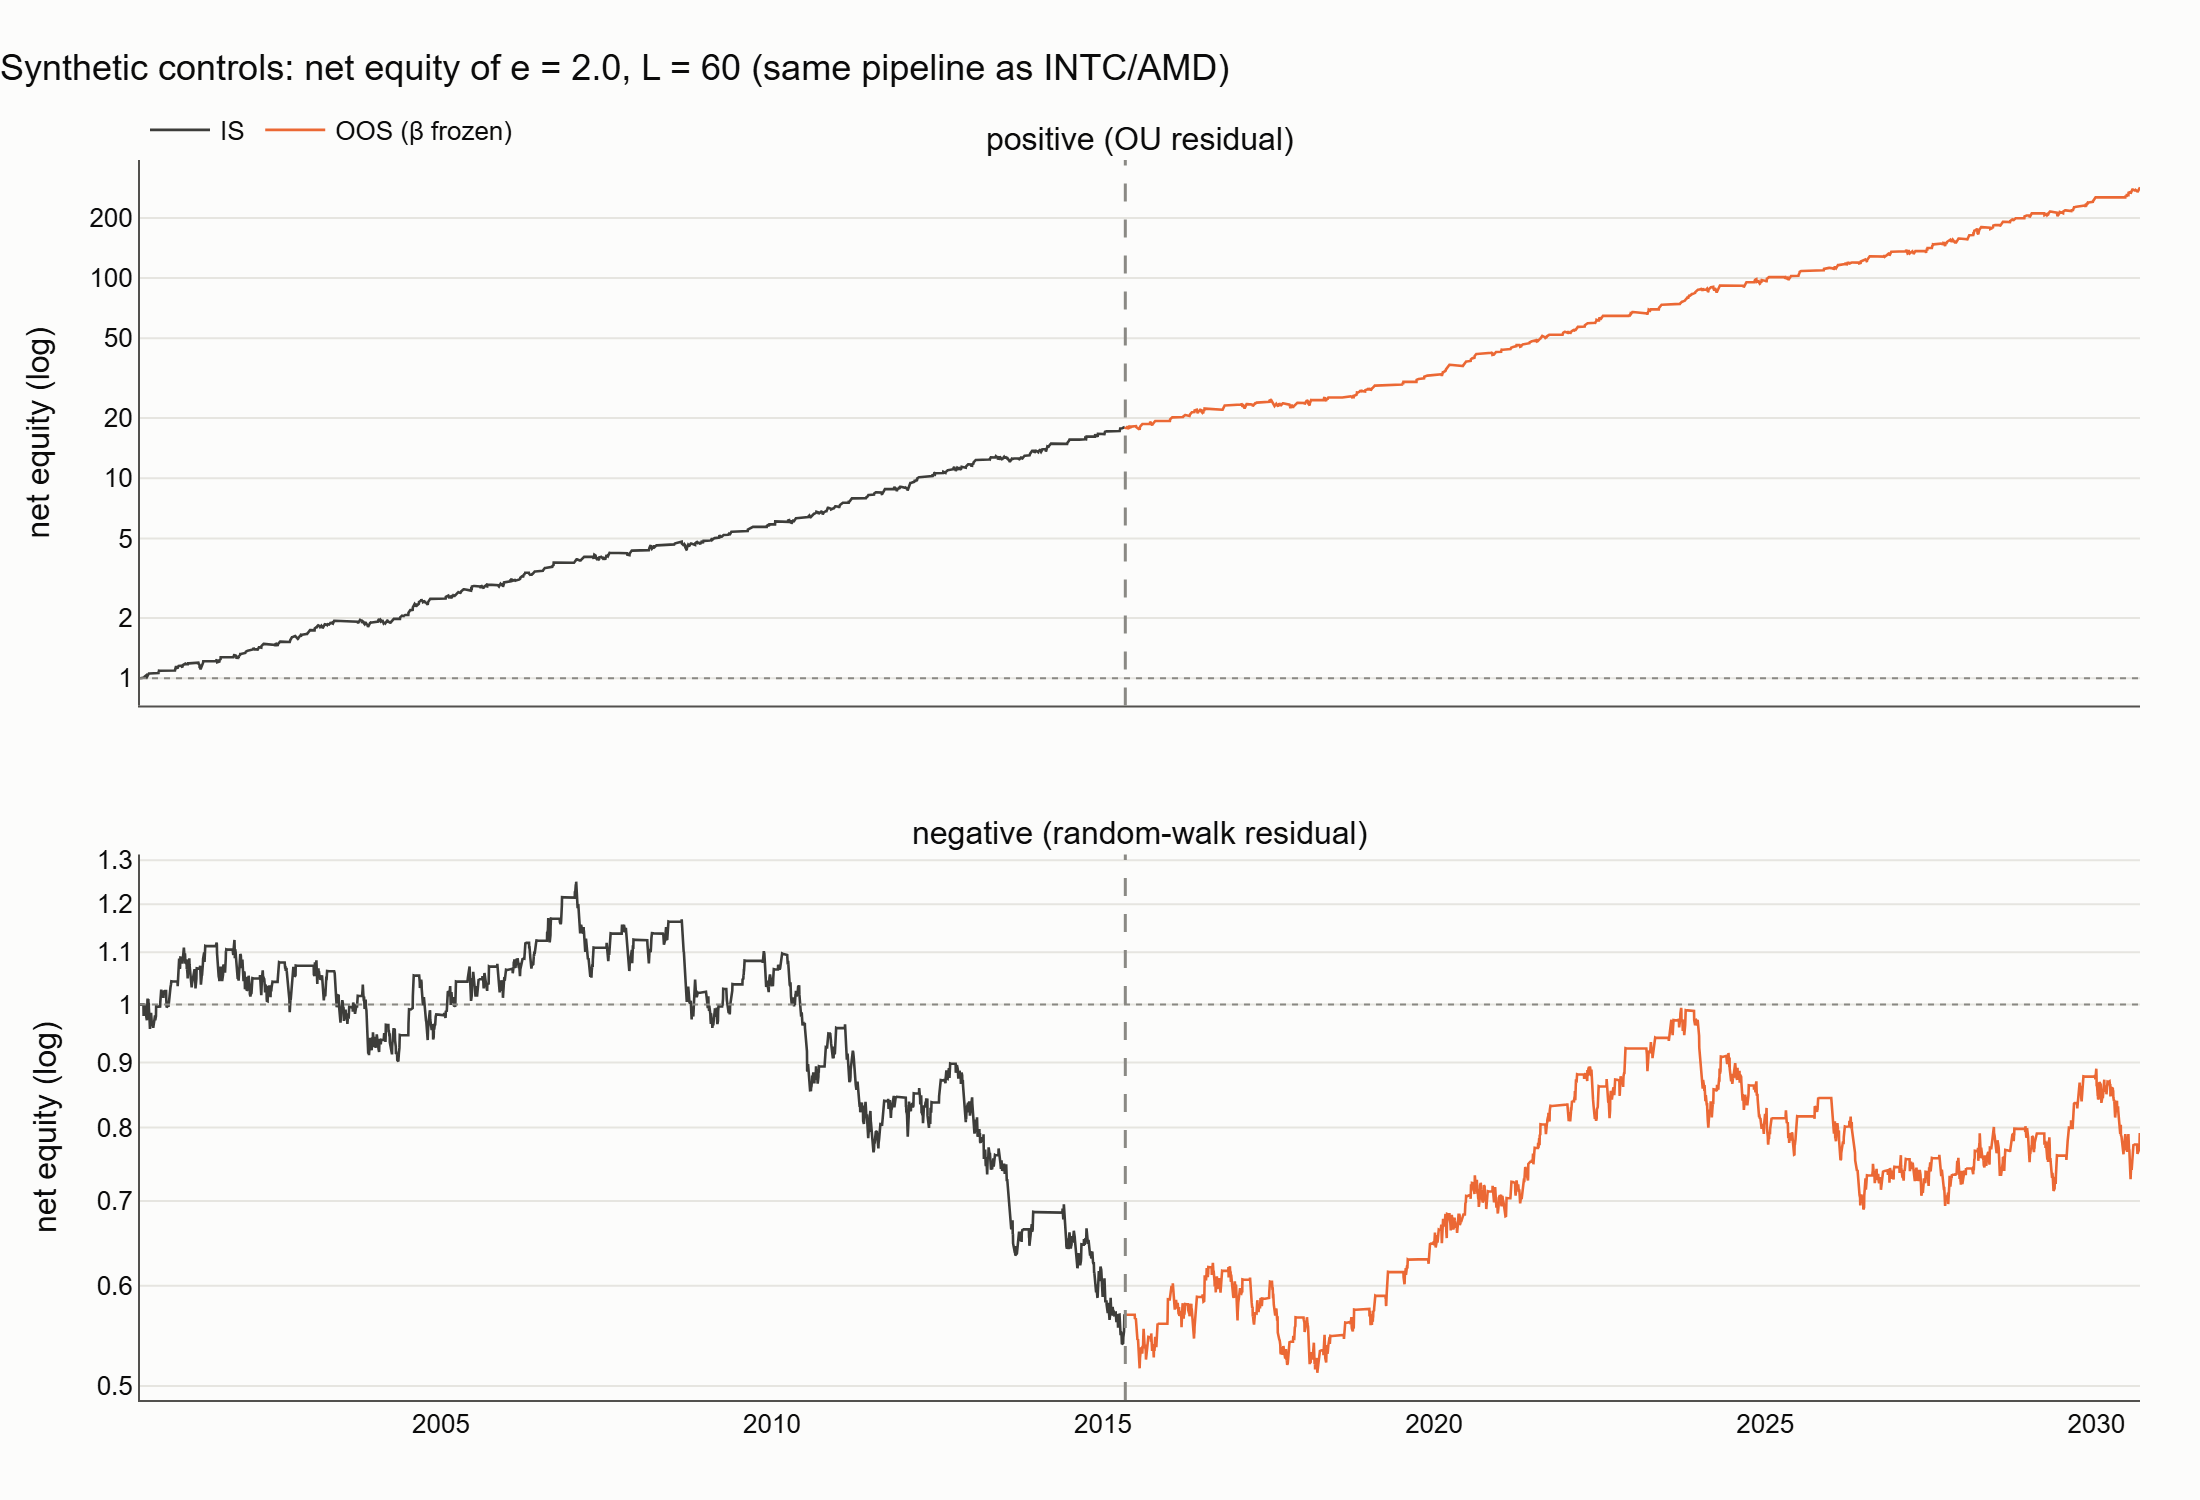

In [3]:
fig = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.12, subplot_titles=list(controls)
)
for row, r in enumerate(controls.values(), start=1):
    eq_is = (1 + r.is_run.daily["net_ret"]).cumprod()
    eq_oos = eq_is.iloc[-1] * (1 + r.oos_run.daily["net_ret"]).cumprod()
    fig.add_trace(
        go.Scatter(
            x=eq_is.index,
            y=eq_is,
            name="IS",
            line={"color": DERIVED_COLOR, "width": 1.3},
            showlegend=row == 1,
        ),
        row=row,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=eq_oos.index,
            y=eq_oos,
            name="OOS (β frozen)",
            line={"color": "#eb6834", "width": 1.3},
            showlegend=row == 1,
        ),
        row=row,
        col=1,
    )
    fig.add_hline(y=1, line={"color": "#8a8984", "width": 1, "dash": "dot"}, row=row, col=1)
    fig.add_vline(
        x=pd.Timestamp(r.split_date),
        line={"color": "#8a8984", "width": 1.5, "dash": "dash"},
        row=row,
        col=1,
    )
    fig.update_yaxes(type="log", title_text="net equity (log)", row=row, col=1)
fig.update_yaxes(tickvals=[1, 2, 5, 10, 20, 50, 100, 200, 500], row=1, col=1)
apply_style(fig, "Synthetic controls: net equity of e = 2.0, L = 60 (same pipeline as INTC/AMD)")
_, png = save_figure(fig, "00_pipeline_controls_equity", height=750)
display(Image(filename=png))

## Reading

- **Positive control:** the pipeline recovers β = 0.800 (true 0.8), Engle–Granger p ≈ 2e-18, half-life 10.7 days (true 10), and the frozen strategy earns a net Sharpe of 1.89 IS and 1.92 OOS with max drawdowns around −9%. When a real mean-reverting relationship exists, this code finds it and trades it profitably, out-of-sample too.
- **Negative control:** Engle–Granger p = 0.62, a spurious β of 1.12, half-life ≈ 423 days, net Sharpe −0.28 IS and +0.24 OOS: no relationship found, no reliable profit.
- **Implication for INTC/AMD:** the real pair (EG p = 0.975, half-life ≈ 6,700 days, Sharpe −0.27 IS / −0.18 OOS) looks like the negative control, not the positive one. The negative result is therefore about the data, not a bug that would hide a real signal.
- Caveat: one seed per control (fixed before running); the positive-control Sharpe depends on the chosen half-life and noise level, which are far more favourable than anything seen in INTC/AMD.